# Layer-wise linear probes for next-token prediction in GPT-2

## 1. Research question and design

**Question.** How well can the next token be linearly decoded from each layer of a pretrained language model, and does that layer-wise pattern differ between predictions the model finds easy and ones it finds hard?

**Design.**
- Model: GPT-2 small (124M parameters, 12 blocks, hidden size 768, vocabulary 50,257), frozen.
- Data: WikiText-2 (raw) Wikipedia articles, split **by article** into train / val / test before any examples are built (a parsing flaw cut 7 articles into pieces; see the audit note in section 3). WebText, GPT-2's training corpus, removed Wikipedia pages, so these articles are unlikely to be memorised verbatim.
- Example: one token position *t* in a 256-token window. Input = hidden state at *t*; label = token at *t+1*.
- Representations: the embedding output (layer 0) and the output of each of the 12 blocks (layers 1–12). In Hugging Face's GPT-2, layer 12 is taken *after* the final LayerNorm, i.e. exactly what the unembedding sees.
- Probe: for each layer, one full-vocabulary linear classifier (768 → 50,257, softmax cross-entropy). The probes share the same examples, optimiser, and early-stopping rule, and differ only in the layer they read.
- Difficulty: GPT-2's own negative log-probability of the true next token (NLL). Tertile thresholds come from the **training** split and are then applied unchanged to the test split: *easy* = lowest third, *hard* = highest third.
- Metric: held-out top-1 accuracy per layer and difficulty group, with 95% bootstrap CIs that resample test **articles** (positions in the same article are not independent).

## 2. Environment, configuration, reproducibility

In [1]:
import copy, hashlib, json, os, platform, time
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers, huggingface_hub
from huggingface_hub import hf_hub_download
from transformers import AutoModelForCausalLM, AutoTokenizer

SEED = 0
MODEL_ID, MODEL_REV = "openai-community/gpt2", "607a30d783dfa663caf39e06633721c8d4cfcd7e"
DATA_ID, DATA_REV = "Salesforce/wikitext", "b08601e04326c79dfdd32d625aee71d232d685c3"
SPLIT_FRACS = {"train": 0.7, "val": 0.1, "test": 0.2}         # fractions of articles
WINDOW = 256                                                   # tokens per window, incl. a leading <|endoftext|>
MIN_CONTEXT = 32                                               # only positions t >= 32, so every example has real context
N_EXAMPLES = {"train": 200_000, "val": 20_000, "test": 40_000}
PROBE = dict(lr_grid=[3e-4, 1e-3, 3e-3], lr_select_layer=6, weight_decay=0.0, batch_size=1024, max_epochs=10, patience=2)
N_BOOT = 1000

CONFIG = dict(seed=SEED, model=MODEL_ID, model_rev=MODEL_REV, data=DATA_ID, data_rev=DATA_REV,
              split_fracs=SPLIT_FRACS, window=WINDOW, min_context=MIN_CONTEXT, n_examples=N_EXAMPLES, probe=PROBE)
CONFIG_HASH = hashlib.sha1(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()[:10]

np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} | hf_hub {huggingface_hub.__version__}")
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else f"({os.cpu_count()} CPU threads)")
if device == "cuda":
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print("config hash:", CONFIG_HASH)

python 3.13.15 | torch 2.11.0+cu130 | transformers 5.20.1 | hf_hub 1.33.0
device: cuda Tesla T4
GPU memory: 15.6 GB
config hash: 9db8894532


## 3. Model and dataset

In [2]:
tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REV)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=MODEL_REV).float().to(device).eval()
model.requires_grad_(False)                       # the language model stays frozen

N_LAYERS = model.config.n_layer + 1               # embedding output + 12 blocks
D, V = model.config.n_embd, model.config.vocab_size
BOS = tok.eos_token_id                            # GPT-2 uses <|endoftext|> as its document separator
print(f"layers probed: {N_LAYERS}, hidden size: {D}, vocab: {V}")
print(f"full-vocab probe: {D * V / 1e6:.1f}M weights = {D * V * 4 / 1e9:.2f} GB fp32 "
      f"(~{D * V * 16 / 1e9:.1f} GB with grads + AdamW state) -> feasible, so no candidate-token restriction")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'TypeError: Failed to fetch'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

layers probed: 13, hidden size: 768, vocab: 50257
full-vocab probe: 38.6M weights = 0.15 GB fp32 (~0.6 GB with grads + AdamW state) -> feasible, so no candidate-token restriction


WikiText-2 ships as one line per row. Top-level headings (` = Title = `) mark the start of an article, so I regroup the lines of all three official files into articles and then re-split them myself with a fixed seed. The raw text escapes some punctuation (`@-@`, `@,@`, `@.@`); I undo that so the text looks like ordinary prose to GPT-2.

**Audit note (added after the run).** This heading rule is too loose. Thirty lines inside tables or formulas (e.g. `= Goals ; A =`) also match it, so seven real articles were cut into several pieces. For five of them the pieces landed in different splits, and 101 of the 40,000 test examples come from a piece whose article also has a piece in train. These pieces share no 33-token span with the training examples, and removing them could change any reported accuracy by at most 0.3 percentage points. A stricter rule would also require a blank line before the title. The code is left exactly as it was run.

In [3]:
def load_articles():
    lines = []
    for split in ["train", "validation", "test"]:
        path = hf_hub_download(DATA_ID, f"wikitext-2-raw-v1/{split}-00000-of-00001.parquet",
                               repo_type="dataset", revision=DATA_REV)
        lines += pd.read_parquet(path)["text"].tolist()
    articles = []
    for line in lines:
        s = line.strip()
        if s.startswith("= ") and s.endswith(" =") and not s.startswith("= ="):
            articles.append([])
        if articles:
            articles[-1].append(line)
    texts = ["".join(a).replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".") for a in articles]
    return list(dict.fromkeys(texts))             # drop exact duplicate articles, keep order

articles = load_articles()
perm = np.random.default_rng(SEED).permutation(len(articles))
n_train, n_val = int(SPLIT_FRACS["train"] * len(perm)), int(SPLIT_FRACS["val"] * len(perm))
split_docs = {"train": perm[:n_train], "val": perm[n_train:n_train + n_val], "test": perm[n_train + n_val:]}
assert not (set(split_docs["train"]) & set(split_docs["val"]) or set(split_docs["train"]) & set(split_docs["test"])
            or set(split_docs["val"]) & set(split_docs["test"]))
print(f"{len(articles)} articles ->", {k: len(v) for k, v in split_docs.items()})
print(articles[split_docs["train"][0]][:300])

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/validation-00000-of-00(…): reconstructing file:   0%|          |  0.00B /  657kB            

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

746 articles -> {'train': 522, 'val': 74, 'test': 150}
 = Cicely Mary Barker = 
 Cicely Mary Barker ( 28 June 1895 – 16 February 1973 ) was an English illustrator best known for a series of fantasy illustrations depicting fairies and flowers . Barker 's art education began in girlhood with correspondence courses and instruction at the Croydon School of 


**Windows and positions.** Each article is tokenised and cut into non-overlapping windows of 255 tokens, and `<|endoftext|>` is prepended to each, giving 256 tokens. A tail shorter than a full window is dropped. Valid prediction positions are *t* = 32…254, and the label is the token at *t*+1. From all valid positions in a split I sample a fixed number without replacement.

`extract` runs the frozen model once per batch of windows. For each sampled position it keeps the 13 hidden states at *t*, GPT-2's own NLL of token *t*+1, and GPT-2's own top-1 prediction.

In [4]:
def make_windows(doc_ids):
    windows, owners = [], []
    for d in doc_ids:
        ids = tok(articles[d], verbose=False).input_ids
        for s in range(0, len(ids) - (WINDOW - 1) + 1, WINDOW - 1):
            windows.append([BOS] + ids[s:s + WINDOW - 1])
            owners.append(d)
    return np.array(windows, dtype=np.int64), np.array(owners)

def sample_positions(n_windows, n, rng):
    per_window = WINDOW - 1 - MIN_CONTEXT          # t in [MIN_CONTEXT, WINDOW - 2]
    flat = np.sort(rng.choice(n_windows * per_window, size=min(n, n_windows * per_window), replace=False))
    return flat // per_window, flat % per_window + MIN_CONTEXT   # (window index, position t), sorted by window

@torch.no_grad()
def extract(windows, w, t, batch=32):
    n = len(w)
    H = torch.empty(N_LAYERS, n, D, dtype=torch.float16)          # fp16 on CPU to save RAM
    nll, model_pred = torch.empty(n), torch.empty(n, dtype=torch.long)
    uniq = np.unique(w)
    for i in range(0, len(uniq), batch):
        ws = uniq[i:i + batch]
        lo, hi = np.searchsorted(w, ws[0]), np.searchsorted(w, ws[-1], side="right")
        ids = torch.from_numpy(windows[ws]).to(device)
        hidden = model.transformer(ids, output_hidden_states=True).hidden_states
        b = torch.from_numpy(np.searchsorted(ws, w[lo:hi])).to(device)
        tt = torch.from_numpy(t[lo:hi]).to(device)
        H[:, lo:hi] = torch.stack([h[b, tt] for h in hidden]).half().cpu()            # state AT t ...
        logits = model.lm_head(hidden[-1][b, tt])                                      # (checked equal to model logits in section 4)
        nll[lo:hi] = F.cross_entropy(logits, ids[b, tt + 1], reduction="none").cpu()     # ... scored on token t+1
        model_pred[lo:hi] = logits.argmax(1).cpu()
    y = torch.from_numpy(windows[w, t + 1])
    return H, y, nll, model_pred

## 4. Feasibility checks and sanity tests

These run on a single short sequence before the full pipeline:
1. hidden-state count, shapes, and finiteness;
2. the logits are exactly the unembedding applied to the layer-12 state;
3. causal alignment: scoring `logits[t]` against `ids[t+1]` reproduces Hugging Face's own shifted LM loss;
4. causality: changing token *t*+1 leaves every hidden state at positions ≤ *t* unchanged, so no probe input can contain its own label.

In [5]:
ids = torch.tensor([[BOS] + tok(articles[split_docs["train"][0]], verbose=False).input_ids[:63]], device=device)
with torch.no_grad():
    out = model(ids, labels=ids, output_hidden_states=True)
hs = out.hidden_states
assert len(hs) == N_LAYERS and all(h.shape == (1, 64, D) for h in hs) and all(torch.isfinite(h).all() for h in hs)

lm_head_diff = (model.lm_head(hs[-1]) - out.logits).abs().max().item()
manual_loss = F.cross_entropy(out.logits[0, :-1], ids[0, 1:])
assert lm_head_diff < 1e-3 and torch.allclose(manual_loss, out.loss, atol=1e-5)

t = 40
ids2 = ids.clone(); ids2[0, t + 1] = (ids[0, t + 1] + 1) % V
with torch.no_grad():
    hs2 = model(ids2, output_hidden_states=True).hidden_states
prefix_diff = max((a[0, :t + 1] - b[0, :t + 1]).abs().max().item() for a, b in zip(hs, hs2))
changed_diff = (hs[-1][0, t + 1] - hs2[-1][0, t + 1]).abs().max().item()
assert prefix_diff < 1e-3 < changed_diff

print("hidden-state shapes:", [tuple(h.shape) for h in hs[:2]], "... x", N_LAYERS)
print(f"max |lm_head(h12) - logits| = {lm_head_diff:.1e}")
print(f"manual shifted NLL = {manual_loss.item():.4f}, HF loss = {out.loss.item():.4f}")
print(f"editing token t+1: max change at positions <= t = {prefix_diff:.1e}, at position t+1 = {changed_diff:.2f}")

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


hidden-state shapes: [(1, 64, 768), (1, 64, 768)] ... x 13
max |lm_head(h12) - logits| = 0.0e+00
manual shifted NLL = 3.9495, HF loss = 3.9495
editing token t+1: max change at positions <= t = 0.0e+00, at position t+1 = 30.12


**Mini end-to-end test.** Extract a small subset (a few thousand train positions and a few hundred validation positions), train one probe on the last layer for a few epochs, and check three things: the loss is finite and falls, the extracted NLL matches the model, and held-out accuracy beats predicting the most common training token.

In [6]:
def standardize(X, mu, sd):
    return (X.float() - mu) / sd

def train_probe(Xtr, ytr, Xva, yva, lr, max_epochs, seed=SEED):
    torch.manual_seed(seed)
    probe = torch.nn.Linear(D, V).to(device)
    opt = torch.optim.AdamW(probe.parameters(), lr=lr, weight_decay=PROBE["weight_decay"])
    g = torch.Generator(device=device).manual_seed(seed)
    best_loss, best_state, history, bad = float("inf"), None, [], 0
    for epoch in range(1, max_epochs + 1):
        order, tr_loss = torch.randperm(len(ytr), generator=g, device=device), 0.0
        for i in range(0, len(order), PROBE["batch_size"]):
            idx = order[i:i + PROBE["batch_size"]]
            loss = F.cross_entropy(probe(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            tr_loss += loss.item() * len(idx)
        va_loss, va_pred = predict(probe, Xva, yva)
        history.append(dict(epoch=epoch, train_loss=tr_loss / len(ytr), val_loss=va_loss,
                            val_acc=(va_pred == yva.cpu()).float().mean().item()))
        if va_loss < best_loss:
            best_loss, best_state, bad = va_loss, copy.deepcopy(probe.state_dict()), 0
        else:
            bad += 1
            if bad >= PROBE["patience"]:
                break
    probe.load_state_dict(best_state)                # early stopping on validation loss
    return probe, history

@torch.no_grad()
def predict(probe, X, y, per_example=False, bs=4096):
    losses, preds = [], []
    for i in range(0, len(y), bs):
        logits = probe(X[i:i + bs])
        losses.append(F.cross_entropy(logits, y[i:i + bs], reduction="none").cpu())
        preds.append(logits.argmax(1).cpu())
    losses, preds = torch.cat(losses), torch.cat(preds)
    return (losses if per_example else losses.mean().item()), preds

start = time.time()
rng = np.random.default_rng(SEED)
mini = {}
for split, n in [("train", 5000), ("val", 1000)]:
    win, _ = make_windows(split_docs[split][:30])
    w, t = sample_positions(len(win), n, rng)
    mini[split] = extract(win, w, t)
H, y, nll, _ = mini["train"]
assert H.shape == (N_LAYERS, len(y), D) and torch.isfinite(H.float()).all() and torch.isfinite(nll).all()
# label of example 0 must be the token right after its position, and its NLL must match a direct forward pass
win, _ = make_windows(split_docs["train"][:30])
w, t = sample_positions(len(win), 5000, np.random.default_rng(SEED))
assert y[0].item() == win[w[0], t[0] + 1]
with torch.no_grad():
    logits0 = model(torch.from_numpy(win[w[:1]]).to(device)).logits[0, t[0]]
assert abs(F.cross_entropy(logits0[None], y[:1].to(device)).item() - nll[0].item()) < 1e-3

mu, sd = H[-1].float().mean(0).to(device), H[-1].float().std(0).to(device) + 1e-6
Xtr, ytr = standardize(H[-1].to(device), mu, sd), y.to(device)
Xva, yva = standardize(mini["val"][0][-1].to(device), mu, sd), mini["val"][1].to(device)
probe, hist = train_probe(Xtr, ytr, Xva, yva, lr=1e-3, max_epochs=3)
majority = torch.mode(y).values.item()
print(pd.DataFrame(hist).round(3).to_string(index=False))
print(f"held-out acc (layer {N_LAYERS - 1}): {hist[-1]['val_acc']:.3f} vs majority-token baseline "
      f"{(mini['val'][1] == majority).float().mean():.3f} | model top-1 {(mini['val'][3] == mini['val'][1]).float().mean():.3f}")
assert all(np.isfinite(h["train_loss"]) for h in hist) and hist[-1]["train_loss"] < hist[0]["train_loss"]
assert max(h["val_acc"] for h in hist) > (mini["val"][1] == majority).float().mean()
print(f"feasibility passed in {time.time() - start:.0f}s")
del mini, H, Xtr, Xva, probe

 epoch  train_loss  val_loss  val_acc
     1      10.783    10.538    0.027
     2       9.488    10.118    0.104
     3       8.289     9.705    0.152
held-out acc (layer 12): 0.152 vs majority-token baseline 0.049 | model top-1 0.342
feasibility passed in 13s


## 5. Dataset preparation and difficulty groups

In [7]:
t0 = time.time()
rng = np.random.default_rng(SEED)
data, keys = {}, {}
for split in ["train", "val", "test"]:
    win, owner = make_windows(split_docs[split])
    w, t = sample_positions(len(win), N_EXAMPLES[split], rng)
    # key = 32 preceding tokens + target; used to catch duplicated contexts across splits
    keys[split] = [win[wi, ti - 31:ti + 2].tobytes() for wi, ti in zip(w, t)]
    data[split] = dict(win=win, w=w, t=t, doc=owner[w])

train_keys = set(keys["train"])
leak = np.array([k in train_keys for k in keys["test"]])
print(f"test examples whose 32-token context + target also occurs in train: {leak.sum()} (removed)")
print(f"val examples with the same overlap: {sum(k in train_keys for k in keys['val'])}")
d = data["test"]
d["w"], d["t"], d["doc"] = d["w"][~leak], d["t"][~leak], d["doc"][~leak]
win_hashes = {s: {x.tobytes() for x in data[s]["win"]} for s in data}
assert not (win_hashes["train"] & win_hashes["test"]) and not (win_hashes["train"] & win_hashes["val"])

for split, d in data.items():
    d["H"], d["y"], d["nll"], d["model_pred"] = extract(d["win"], d["w"], d["t"])
    assert torch.isfinite(d["nll"]).all()
split_table = pd.DataFrame({s: dict(articles=len(split_docs[s]), windows=len(d["win"]), examples=len(d["y"]),
                                    articles_with_examples=len(np.unique(d["doc"])))
                            for s, d in data.items()}).T
print(split_table.to_string())
print(f"extraction took {time.time() - t0:.0f}s")

test examples whose 32-token context + target also occurs in train: 0 (removed)
val examples with the same overlap: 0
       articles  windows  examples  articles_with_examples
train       522     7670    200000                     515
val          74      945     20000                      70
test        150     2255     40000                     146
extraction took 207s


**Difficulty thresholds** are the 1/3 and 2/3 quantiles of GPT-2's NLL on the *training* examples. They are fixed before any probe is trained and applied unchanged to validation and test. The table also lists two descriptors of possible confounds: how frequent the target token is in the probe-training labels, and what share of targets are among the 100 most frequent tokens.

In [8]:
q_easy, q_hard = np.quantile(data["train"]["nll"].numpy(), [1 / 3, 2 / 3])
def group_of(nll):
    return np.where(nll <= q_easy, "easy", np.where(nll > q_hard, "hard", "medium"))
for d in data.values():
    d["group"] = group_of(d["nll"].numpy())
print(f"thresholds (nats): easy <= {q_easy:.3f} < medium <= {q_hard:.3f} < hard")

train_counts = np.bincount(data["train"]["y"].numpy(), minlength=V)
top100 = np.argsort(-train_counts)[:100]
majority = int(train_counts.argmax())
test = data["test"]
y_test = test["y"].numpy()
rows = []
for g in ["easy", "medium", "hard", "all"]:
    m = np.ones(len(y_test), bool) if g == "all" else test["group"] == g
    rows.append(dict(group=g, n_test=int(m.sum()), mean_model_nll=test["nll"].numpy()[m].mean(),
                     model_top1=(test["model_pred"].numpy()[m] == y_test[m]).mean(),
                     majority_baseline=(y_test[m] == majority).mean(),
                     median_target_train_count=np.median(train_counts[y_test[m]]),
                     frac_target_in_top100=np.isin(y_test[m], top100).mean(),
                     frac_target_unseen_in_train=(train_counts[y_test[m]] == 0).mean()))
group_table = pd.DataFrame(rows).set_index("group")
print(f"majority token: {tok.decode([majority])!r}")
print(group_table.round(3).to_string())
assert group_table.loc[["easy", "hard"], "n_test"].min() >= 1000

thresholds (nats): easy <= 1.625 < medium <= 4.381 < hard
majority token: ' the'
        n_test  mean_model_nll  model_top1  majority_baseline  median_target_train_count  frac_target_in_top100  frac_target_unseen_in_train
group                                                                                                                                       
easy     13298           0.642       0.921              0.102                      958.0                  0.605                        0.037
medium   13535           2.894       0.141              0.047                      268.0                  0.549                        0.026
hard     13167           6.992       0.000              0.003                       14.0                  0.183                        0.093
all      40000           3.494       0.354              0.051                       78.0                  0.447                        0.052


## 6. Probe training and evaluation

The same procedure is used for every layer:
- standardise features with the train mean and std of that layer;
- full-vocabulary linear probe, AdamW, batch size 1024, zero weight decay;
- one learning rate for all layers, chosen from a small grid by **validation** loss on a middle layer (layer 6);
- up to `max_epochs` epochs, keeping the epoch with the lowest **validation** loss (patience 2);
- evaluate once on the identical test set.

Validation is used only for this stopping rule, and test data is never used during training. Per-layer test predictions are cached under `cache/`, keyed by the config hash.

In [9]:
os.makedirs("cache", exist_ok=True)
cache_path = f"cache/probe_test_outputs_{CONFIG_HASH}"

def layer_features(layer):
    Htr = data["train"]["H"][layer].to(device)
    mu, sd = Htr.float().mean(0), Htr.float().std(0) + 1e-6
    return [standardize(data[s]["H"][layer].to(device), mu, sd) for s in ["train", "val", "test"]]
y_dev = {s: data[s]["y"].to(device) for s in data}

if os.path.exists(cache_path + ".npz"):
    c = np.load(cache_path + ".npz")
    test_pred, test_nll = c["pred"], c["nll"]
    log = json.load(open(cache_path + ".json"))
    print("loaded cached probe outputs from", cache_path)
else:
    Xtr, Xva, _ = layer_features(PROBE["lr_select_layer"])
    lr_scores = {}
    for lr in PROBE["lr_grid"]:
        _, hist = train_probe(Xtr, y_dev["train"], Xva, y_dev["val"], lr=lr, max_epochs=PROBE["max_epochs"])
        lr_scores[lr] = min(h["val_loss"] for h in hist)
        print(f"lr {lr:g}: best val loss {lr_scores[lr]:.3f} after {len(hist)} epochs")
    lr = min(lr_scores, key=lr_scores.get)
    print(f"selected lr = {lr:g} (used for every layer)")

    test_pred = np.zeros((N_LAYERS, len(y_test)), dtype=np.int64)
    test_nll = np.zeros((N_LAYERS, len(y_test)), dtype=np.float32)
    log = dict(lr_scores=lr_scores, lr=lr, histories=[])
    for layer in range(N_LAYERS):
        start = time.time()
        Xtr, Xva, Xte = layer_features(layer)
        probe, hist = train_probe(Xtr, y_dev["train"], Xva, y_dev["val"], lr=lr, max_epochs=PROBE["max_epochs"])
        nll_te, pred_te = predict(probe, Xte, y_dev["test"], per_example=True)
        test_pred[layer], test_nll[layer] = pred_te.numpy(), nll_te.numpy()
        log["histories"].append(hist)
        best = min(hist, key=lambda h: h["val_loss"])
        print(f"layer {layer:2d}: best epoch {best['epoch']} / {len(hist)}, val loss {best['val_loss']:.3f}, "
              f"val acc {best['val_acc']:.3f}, test acc {(test_pred[layer] == y_test).mean():.3f} ({time.time() - start:.0f}s)")
        del Xtr, Xva, Xte, probe
    np.savez(cache_path + ".npz", pred=test_pred, nll=test_nll)
    json.dump(log, open(cache_path + ".json", "w"))
histories = log["histories"]
assert np.isfinite(test_nll).all()

lr 0.0003: best val loss 5.960 after 10 epochs
lr 0.001: best val loss 6.012 after 5 epochs
lr 0.003: best val loss 6.320 after 3 epochs
selected lr = 0.0003 (used for every layer)
layer  0: best epoch 7 / 9, val loss 7.186, val acc 0.147, test acc 0.149 (133s)
layer  1: best epoch 9 / 10, val loss 6.917, val acc 0.169, test acc 0.172 (148s)
layer  2: best epoch 10 / 10, val loss 6.725, val acc 0.181, test acc 0.187 (147s)
layer  3: best epoch 10 / 10, val loss 6.491, val acc 0.204, test acc 0.206 (148s)
layer  4: best epoch 9 / 10, val loss 6.304, val acc 0.217, test acc 0.216 (147s)
layer  5: best epoch 9 / 10, val loss 6.179, val acc 0.226, test acc 0.225 (147s)
layer  6: best epoch 9 / 10, val loss 5.960, val acc 0.243, test acc 0.238 (147s)
layer  7: best epoch 9 / 10, val loss 5.760, val acc 0.256, test acc 0.251 (147s)
layer  8: best epoch 9 / 10, val loss 5.509, val acc 0.274, test acc 0.268 (148s)
layer  9: best epoch 9 / 10, val loss 5.288, val acc 0.289, test acc 0.285 (147s

## 7. Results

These cells write `results.csv`, `main_figure.png` and `metadata.json` to the working directory. In the repository they are stored unchanged as `results/layerwise_accuracy.csv`, `results/main_figure.png` and `results/metadata.json`.

In [10]:
correct = test_pred == y_test[None]                    # (layers, test examples)
docs, inv = np.unique(test["doc"], return_inverse=True)
boot = np.random.default_rng(SEED)
boot_counts = np.stack([np.bincount(boot.integers(0, len(docs), len(docs)), minlength=len(docs)) for _ in range(N_BOOT)])

def acc_with_ci(values, mask):
    # article-level bootstrap: resample test articles, recompute the pooled mean
    per_doc_sum = np.bincount(inv[mask], weights=values[mask], minlength=len(docs))
    per_doc_n = np.bincount(inv[mask], minlength=len(docs))
    stats = boot_counts @ per_doc_sum / np.maximum(boot_counts @ per_doc_n, 1)
    return values[mask].mean(), *np.percentile(stats, [2.5, 97.5])

masks = {"all": np.ones(len(y_test), bool), **{g: test["group"] == g for g in ["easy", "medium", "hard"]}}
rows = []
for layer in range(N_LAYERS):
    row = dict(layer=layer, best_epoch=min(histories[layer], key=lambda h: h["val_loss"])["epoch"])
    for g, m in masks.items():
        row[f"acc_{g}"], row[f"acc_{g}_lo"], row[f"acc_{g}_hi"] = acc_with_ci(correct[layer].astype(float), m)
        row[f"probe_nll_{g}"] = test_nll[layer][m].mean()
    rows.append(row)
results = pd.DataFrame(rows)
results.round(4).to_csv("results.csv", index=False)
show = ["layer", "acc_all", "acc_easy", "acc_easy_lo", "acc_easy_hi", "acc_hard", "acc_hard_lo", "acc_hard_hi",
        "probe_nll_easy", "probe_nll_hard", "best_epoch"]
print(results[show].round(3).to_string(index=False))
print("\nreference (same test examples):")
print(group_table[["n_test", "model_top1", "majority_baseline"]].round(3).to_string())

 layer  acc_all  acc_easy  acc_easy_lo  acc_easy_hi  acc_hard  acc_hard_lo  acc_hard_hi  probe_nll_easy  probe_nll_hard  best_epoch
     0    0.149     0.300        0.287        0.312     0.032        0.028        0.036           5.157           9.738           7
     1    0.172     0.352        0.336        0.366     0.037        0.033        0.041           4.753           9.649           9
     2    0.187     0.387        0.371        0.401     0.036        0.032        0.040           4.492           9.575          10
     3    0.206     0.424        0.406        0.438     0.040        0.036        0.044           4.198           9.449          10
     4    0.216     0.445        0.430        0.459     0.041        0.037        0.046           3.998           9.302           9
     5    0.225     0.464        0.448        0.478     0.043        0.039        0.047           3.843           9.223           9
     6    0.238     0.498        0.482        0.512     0.043        0.039  

**Main figure.** Left: absolute held-out top-1 accuracy, with shaded 95% article-bootstrap CIs. Right: each curve divided by its own maximum over layers, which shows *where* each group's decodable information appears, independent of its overall level.

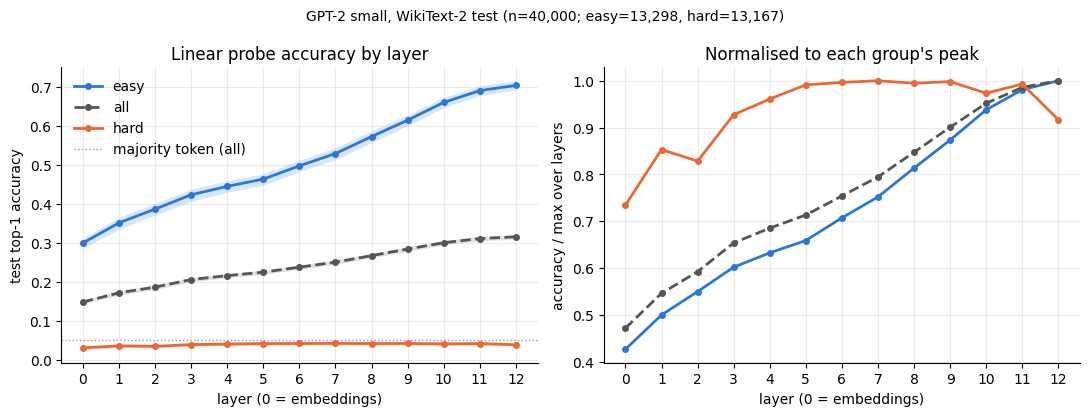

In [11]:
colors = {"easy": "#2a78d6", "hard": "#eb6834", "all": "#555555"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
L = results["layer"]
for g in ["easy", "all", "hard"]:
    a = results[f"acc_{g}"]
    style = dict(color=colors[g], lw=2, ls="--" if g == "all" else "-", marker="o", ms=4)
    axes[0].plot(L, a, label=g, **style)
    axes[0].fill_between(L, results[f"acc_{g}_lo"], results[f"acc_{g}_hi"], color=colors[g], alpha=0.18, lw=0)
    axes[1].plot(L, a / a.max(), label=g, **style)
axes[0].axhline(group_table.loc["all", "majority_baseline"], color="#999999", lw=1, ls=":", label="majority token (all)")
axes[0].set(xlabel="layer (0 = embeddings)", ylabel="test top-1 accuracy", title="Linear probe accuracy by layer")
axes[1].set(xlabel="layer (0 = embeddings)", ylabel="accuracy / max over layers", title="Normalised to each group's peak")
for ax in axes:
    ax.set_xticks(range(N_LAYERS)); ax.grid(alpha=0.25); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.suptitle(f"GPT-2 small, WikiText-2 test (n={len(y_test):,}; easy={masks['easy'].sum():,}, hard={masks['hard'].sum():,})", fontsize=10)
fig.tight_layout()
fig.savefig("main_figure.png", dpi=150)
plt.show()

In [12]:
def first_layer_reaching(g, frac=0.9):
    a = results[f"acc_{g}"].to_numpy()
    return int(np.argmax(a >= frac * a.max()))
summary = {g: dict(peak_layer=int(results[f"acc_{g}"].idxmax()), peak_acc=results[f"acc_{g}"].max(),
                   layer12_acc=results[f"acc_{g}"].iloc[-1], first_layer_90pct_of_peak=first_layer_reaching(g),
                   model_top1=group_table.loc[g, "model_top1"])
           for g in ["easy", "medium", "hard", "all"]}
print(pd.DataFrame(summary).T.round(3).to_string())

metadata = dict(config=CONFIG, config_hash=CONFIG_HASH, device=device, selected_lr=log["lr"],
                versions=dict(python=platform.python_version(), torch=torch.__version__, transformers=transformers.__version__),
                n_articles=len(articles), split_table=split_table.to_dict(orient="index"),
                removed_test_overlaps=int(leak.sum()), difficulty_thresholds_nats=dict(easy_max=q_easy, hard_min=q_hard),
                majority_token=tok.decode([majority]), group_table=group_table.round(4).to_dict(orient="index"),
                summary=summary)
with open("metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=float)

        peak_layer  peak_acc  layer12_acc  first_layer_90pct_of_peak  model_top1
easy          12.0     0.704        0.704                       10.0       0.921
medium        12.0     0.204        0.204                        8.0       0.141
hard           7.0     0.043        0.039                        3.0       0.000
all           12.0     0.316        0.316                        9.0       0.354


## 8. Interpretation and limitations

*Revised after a post-run audit; code and outputs above are unchanged. The audit is summarised in `results.md`.*

**Observed** (40,000 test positions from 146 held-out articles; CIs resample articles):
- All tokens: probe accuracy rises at every layer, from 14.9% (embeddings) to 31.6% (layer 12), with no intermediate peak.
- Easy group: 30.0% → 70.4%, still rising at layer 12.
- Hard group: 3.2% at layer 0, about 4.3% for layers 5–11, 3.9% at layer 12. The CIs for layers 0 and 5 do not overlap, while those for layers 11 and 12 do. Paired CIs for layer differences were not computed, so treat both the small rise and the final dip as tentative. Probe cross-entropy on hard tokens falls steadily (9.74 → 8.39 nats).
- GPT-2's own top-1 on the same positions: easy 92.1%, medium 14.1%, hard 0 of 13,167. That zero is an observation, not a consequence of the definition. On 55 hard examples GPT-2's top token itself had probability below the 1.25% threshold, so a correct top-1 was possible there, but none occurred.

**Supported:** in GPT-2 small on this data, a linear probe reads out the next token more easily at deeper layers. The gain is concentrated in positions GPT-2 itself predicts well; positions it predicts badly stay hard to decode at every layer.

**Not established:**
- *Difficulty vs frequency.* Hard targets are much rarer among the probe's training labels: per-example median count 14 vs 958 for easy, and 9.3% vs 3.7% never seen. The groups do overlap in frequency (1,462 hard examples have targets seen ≥1,000 times), so a frequency-matched comparison is possible in principle. It was not done, because the per-example probe predictions were lost with the Colab session. The easy/hard gap may be partly or mostly a frequency effect.
- *Use.* A probe shows that information is decodable from a layer, not that GPT-2 uses it there.
- *Probe > model.* The probe beats GPT-2's top-1 on medium (20.4% vs 14.1%) and hard (3.9% vs 0%). This is probably a selection effect, since these groups are chosen for GPT-2 giving the true token low probability. That is a hypothesis, not tested here.

**Comparability across layers:**
- Every layer uses the same examples, labels, standardisation rule, learning rate, epoch cap and early-stopping rule. The learning rate (3e-4) was chosen on layer 6 validation loss and is the smallest value in the grid.
- Only layers 2 and 3 were still improving at the 10-epoch cap. Layer 0 stopped early (best epoch 7), and the other layers peaked at epoch 9. Absolute accuracies are likely somewhat below what better-tuned probes would reach.
- On layer 6, the two best learning rates differ by 0.05 nats of validation loss, less than every gap between adjacent layers (0.12–0.27 nats). The overall upward trend is therefore unlikely to come from the learning-rate choice. Differences of about 1 point (the hard group, layer 11 vs 12) are small enough that tuning could change them.
- Layer 12 is the state after the final LayerNorm, while layers 0–11 are the raw residual stream, so the last step compares slightly different kinds of vector.
- The right panel of the figure divides each curve by its own peak. For the hard group this stretches a range of about one point and should not be read as strong structure.

**Scope:** one model, one dataset, one probe seed, contexts of 32–254 tokens.
